# HW 8, Problem 1: Experimental design

Both filters (EKF in Problem 2, stochastic EnKF in Problem 3) are compared on the **same** saved truth and observations, generated once here for each of the two selected models. Every shared setting lives in `src/da_models/hw8.py`; Problems 2–4 load the files saved below and never regenerate them.

## Setup

* **Models.** One-layer Lorenz–96 with the HW 1 values ($K = 40$, $F = 8$, $d = 1$), started from the saved HW 1 state (`data/lorenz96_ic.npy`). Two-layer Lorenz–96 **reduced** to $K = 10$, $J = 2$ for a less expensive dense EKF, keeping $F = 8$, $d = 1$, $\gamma_j = 0.05$, $(d_1, d_2) = (0.2, 0.5)$. The reduced system is spun up again below (HW 1 start: $u_k = F$, $u_0 = F + 0.01$, $v_{k,j} = 0$).
* **Model map.** $\mathcal M_{k-1}$ advances the deterministic model by $\delta t = 0.1$ with the HW 1 solver: `scipy.integrate.solve_ivp`, RK45 (adaptive), `rtol = atol = 1e-9`. The observation interval $\delta t$ is not the solver step. The same model is used for the truth and the filters, and $Q_{k-1} = 0$.
* **Observations.** $y_k = Hx_k^\dagger + v_k$, $v_k \sim N(0, R)$ independent across $k$, at $t_k = k\,\delta t$, $k = 1, \dots, L$, with $T = 10$ and $L = 100$ (no observation at $t_0$). $H$ selects every second $u_k$ ($u_0, u_2, \dots$); all $v_{k,j}$ are hidden. $R = I_p$.
* **Prior.** $m_0^a = x_0^\dagger + 0.1D\mathbf 1$ and $P_0^a = 0.01D^2$, with $D$ the diagonal matrix of state scales described below. Neither Lorenz–96 model has a restricted state domain, so this prior is used as given.
* **Random streams.** Observation noise: `default_rng([513, 0, model])`, with `model` = 0 (one-layer) or 1 (two-layer). The EnKF streams for later problems are fixed in `hw8.py`: initial members `default_rng([513, 1, model, Ne, r])` and observation perturbations `default_rng([513, 2, model, Ne, r])`.
* **Saved data.** `data/hw8_twin_l96.npz` and `data/hw8_twin_l96_2layer.npz`: truth, observations, free forecast, $H$, $R$, $D$, prior, and the settings that produced them. If a file already exists it is loaded, not regenerated (set `REGENERATE = True` to rebuild).

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from da_models import hw8, lorenz96
from da_models.assimilation import flatten
from da_models.climatology import (long_run, time_average_stats, convergence_check,
                                   save_climatology)

DATA_DIR = Path("../data")   # adjust if running in Colab
REGENERATE = False           # True rebuilds the saved twin data (truth + observations)
NAMES = ("l96", "l96_2layer")

np.set_printoptions(precision=4, suppress=True, linewidth=110)
C = dict(truth="#0b0b0b", free="#8c8a85", obs="#eb6834")
plt.rcParams.update({
    "axes.grid": True, "grid.color": "0.9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.2, "legend.frameon": False, "figure.dpi": 110,
})

## Spin-up and climatology for the reduced two-layer model

Spin up for $T_{\text{spin}} = 500$ time units from the HW 1 starting state (the slowest secondary variables relax on the time scale $1/d_1 = 5$), save the final state as $x_0^\dagger$, then run 5000 more time units from it and record time-averaged statistics as in HW 5 (`climatology.py`: trapezoid time averages after discarding the first 50 time units, sampled every 0.05). The climatology is used only to set $D$. The one-layer model reuses its HW 1 state and HW 5 climatology.

In [2]:
spec = hw8.MODELS["l96_2layer"]
K2, J2 = spec["K"], spec["J"]
ic_path, clim_path = DATA_DIR / spec["ic_file"], DATA_DIR / spec["clim_file"]
T_SPIN, T_CLIM, T_BURN, DT_SAMPLE = 500.0, 5000.0, 50.0, 0.05

if ic_path.exists() and clim_path.exists():
    print(f"Using saved {ic_path.name} and {clim_path.name}")
else:
    u_start = 8.0 * np.ones(K2)
    u_start[0] += 0.01                                     # HW 1 starting state
    x_start = lorenz96.pack_two_layer(u_start, np.zeros((K2, J2)))
    _, X = long_run(spec["rhs"], x_start, T_SPIN, 1.0, spec["params"])
    np.save(ic_path, X[-1])

    t, X = long_run(spec["rhs"], X[-1], T_CLIM, DT_SAMPLE, spec["params"])
    mu, B = time_average_stats(t, X, T_BURN)
    d_mu, d_B = convergence_check(t, X, T_BURN)
    print(f"Climatology convergence (relative change between halves): mean {d_mu:.1e}, covariance {d_B:.1e}")
    save_climatology(clim_path, "lorenz96_two_layer", mu, B, params=spec["params"],
                     state_labels=hw8.state_labels("l96_2layer"), t_start=T_BURN,
                     t_final=T_CLIM, dt=DT_SAMPLE,
                     notes=f"HW 8 reduced system, spun up {T_SPIN:g} time units from the HW 1 start")
    print(f"Saved {ic_path.name} and {clim_path.name}")

Using saved lorenz96_two_layer_K10_J2_ic.npy and climatology_lorenz96_two_layer_K10_J2.json


## Experiment specifications

In [3]:
models = {name: hw8.load_model(name, DATA_DIR) for name in NAMES}

def short_list(labels, head=4, tail=2):
    return ", ".join(labels) if len(labels) <= head + tail else \
        ", ".join(labels[:head]) + ", ..., " + ", ".join(labels[-tail:])

for name, mdl in models.items():
    p = mdl["H"].shape[0]
    hidden = [lab for i, lab in enumerate(mdl["labels"]) if i not in set(mdl["observed"])]
    print(f"=== {mdl['title']} ===")
    print(f"dimension n = {mdl['n']};  state order: {short_list(mdl['labels'])}")
    print(f"parameters: {mdl['params']}")
    print(f"solver: solve_ivp {hw8.SOLVER['method']}, rtol = {hw8.SOLVER['rtol']:g}, atol = {hw8.SOLVER['atol']:g}")
    print(f"observation interval dt = {hw8.DT_OBS}, T = {hw8.T_FINAL:g}, L = {hw8.L}")
    print(f"observed (p = {p}): {short_list([mdl['labels'][i] for i in mdl['observed']])}")
    print(f"hidden ({len(hidden)}): {short_list(hidden)}")
    print(f"H is {p} x {mdl['n']} with H[i, 2i] = 1 and zeros elsewhere: "
          f"{np.array_equal(np.argwhere(mdl['H']), np.column_stack([np.arange(p), 2 * np.arange(p)]))}")
    print(f"R = I_{p}: {np.array_equal(mdl['R'], np.eye(p))}\n")

print("Two-layer H (5 x 30), columns u0..u9 | v0,1 v0,2 ... v9,2:")
print(models["l96_2layer"]["H"].astype(int))

=== One-layer Lorenz-96 ===
dimension n = 40;  state order: u0, u1, u2, u3, ..., u38, u39
parameters: {'F': 8.0, 'd': 1.0}
solver: solve_ivp RK45, rtol = 1e-09, atol = 1e-09
observation interval dt = 0.1, T = 10, L = 100
observed (p = 20): u0, u2, u4, u6, ..., u36, u38
hidden (20): u1, u3, u5, u7, ..., u37, u39
H is 20 x 40 with H[i, 2i] = 1 and zeros elsewhere: True
R = I_20: True

=== Two-layer Lorenz-96 (K = 10, J = 2) ===
dimension n = 30;  state order: u0, u1, u2, u3, ..., v9,1, v9,2
parameters: {'K': 10, 'J': 2, 'F': 8.0, 'd': 1.0, 'gamma': 0.05, 'd_j': (0.2, 0.5)}
solver: solve_ivp RK45, rtol = 1e-09, atol = 1e-09
observation interval dt = 0.1, T = 10, L = 100
observed (p = 5): u0, u2, u4, u6, u8
hidden (25): u1, u3, u5, u7, ..., v9,1, v9,2
H is 5 x 30 with H[i, 2i] = 1 and zeros elsewhere: True
R = I_5: True

Two-layer H (5 x 30), columns u0..u9 | v0,1 v0,2 ... v9,2:
[[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0

## State scales $D$ and the prior

For each family of statistically identical variables ($u$; and $v_{:,1}$, $v_{:,2}$ in the two-layer model), $D$ is the square root of the site-averaged climatological variance. The table compares it with the per-site climatological standard deviations and also lists the family's climatological mean. The checks below confirm the prior: the truth sits exactly one prior standard deviation from $m_0^a$ in every component, so its Mahalanobis distance from $m_0^a$ is $\sqrt n$.

In [4]:
for name, mdl in models.items():
    sd_site = np.sqrt(np.diag(mdl["B"]))
    print(f"=== {mdl['title']} ===")
    print(f"{'family':>8} {'D':>8} {'per-site sd (min, max)':>24} {'clim. mean':>11}")
    for fam, idx in hw8.variable_families(name).items():
        print(f"{fam:>8} {mdl['D'][idx[0]]:8.4f} {sd_site[idx].min():11.4f}, {sd_site[idx].max():.4f} "
              f"{mdl['mu'][idx].mean():11.4f}")

    shift = (mdl["m0"] - mdl["x0"]) / mdl["D"]
    e = mdl["x0"] - mdl["m0"]
    maha = np.sqrt(e @ np.linalg.solve(mdl["P0"], e))
    print(f"(m0 - x0)/D = {shift.min():.3f} .. {shift.max():.3f};  "
          f"sqrt(diag P0)/D = {np.unique(np.round(np.sqrt(np.diag(mdl['P0'])) / mdl['D'], 12))};  "
          f"Mahalanobis distance of x0 from m0 = {maha:.4f} (sqrt(n) = {np.sqrt(mdl['n']):.4f})")
    if mdl["J"]:
        v_idx = np.arange(mdl["K"], mdl["n"])
        print(f"largest v in x0: {mdl['x0'][v_idx].max():.4f};  in m0: {mdl['m0'][v_idx].max():.4f}")
    print()

=== One-layer Lorenz-96 ===
  family        D   per-site sd (min, max)  clim. mean
       u   3.6389      3.5917, 3.6761      2.3393
(m0 - x0)/D = 0.100 .. 0.100;  sqrt(diag P0)/D = [0.1];  Mahalanobis distance of x0 from m0 = 6.3246 (sqrt(n) = 6.3246)

=== Two-layer Lorenz-96 (K = 10, J = 2) ===
  family        D   per-site sd (min, max)  clim. mean
       u   3.0250      3.0083, 3.0445      2.3906
      v1   0.9520      0.9288, 0.9810     -3.7160
      v2   0.6482      0.6318, 0.6660     -1.4865
(m0 - x0)/D = 0.100 .. 0.100;  sqrt(diag P0)/D = [0.1];  Mahalanobis distance of x0 from m0 = 5.4772 (sqrt(n) = 5.4772)
largest v in x0: -0.9287;  in m0: -0.8639



**Explanation of $D$.** *Explain the entries of $D$ for each model: what they measure, why one value per variable family, and why the two $v$ families get different scales from each other and from $u$.*

$D$ scales the different variables so we get a fair comparison between them and determines the uncertainty of the initial state.



## Truth, observations, and free forecast

One truth trajectory per model from $x_0^\dagger$, observations from the data stream, and a free forecast: the same model run from $m_0^a$ with no assimilation.

In [5]:
twins = {}
for name, mdl in models.items():
    path = hw8.twin_path(name, DATA_DIR)
    if REGENERATE or not path.exists():
        twin = hw8.build_twin(mdl)
        hw8.save_twin(mdl, twin, DATA_DIR)
        print(f"{mdl['title']}: generated and saved {path.name} "
              f"(free forecast took {twin['free_runtime']:.3f} s)")
    else:
        print(f"{mdl['title']}: loaded saved {path.name}")
    tw = hw8.load_twin(name, DATA_DIR)
    # the saved data must match the current settings
    assert tw["meta"]["params"] == {k: list(v) if isinstance(v, tuple) else v
                                    for k, v in mdl["params"].items()}
    assert np.array_equal(tw["x0"], mdl["x0"]) and np.array_equal(tw["H"], mdl["H"])
    assert np.array_equal(tw["D"], mdl["D"]) and np.array_equal(tw["m0"], mdl["m0"])
    twins[name] = tw
    print(f"   x_true {tw['x_true'].shape}, Y {tw['Y'].shape}, free forecast {tw['x_free'].shape}")

One-layer Lorenz-96: loaded saved hw8_twin_l96.npz
   x_true (101, 40), Y (100, 20), free forecast (101, 40)
Two-layer Lorenz-96 (K = 10, J = 2): loaded saved hw8_twin_l96_2layer.npz
   x_true (101, 30), Y (100, 5), free forecast (101, 30)


Sanity plot in physical (model) units: one observed and one hidden $u$ for each model, plus one secondary variable of each family for the two-layer model. Observations appear on the observed panel only.

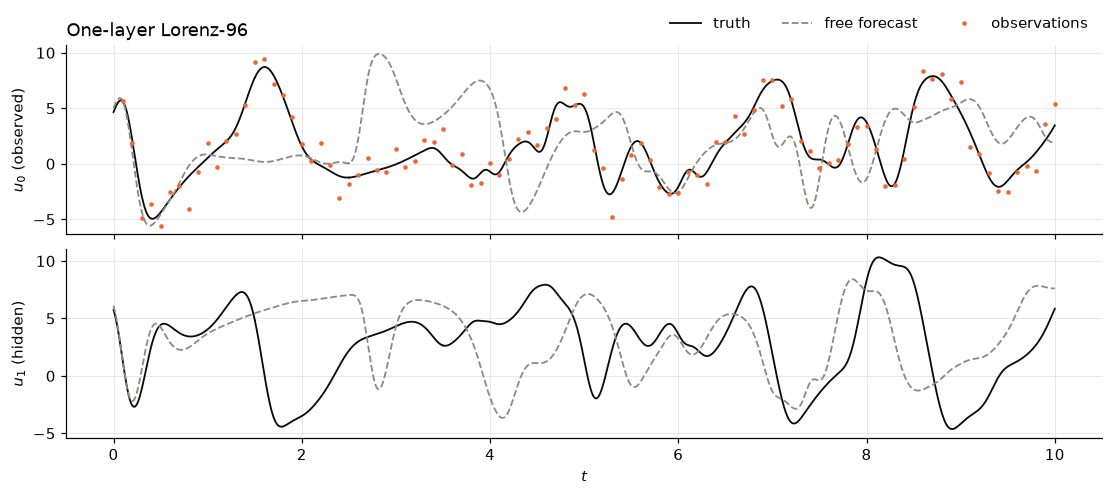

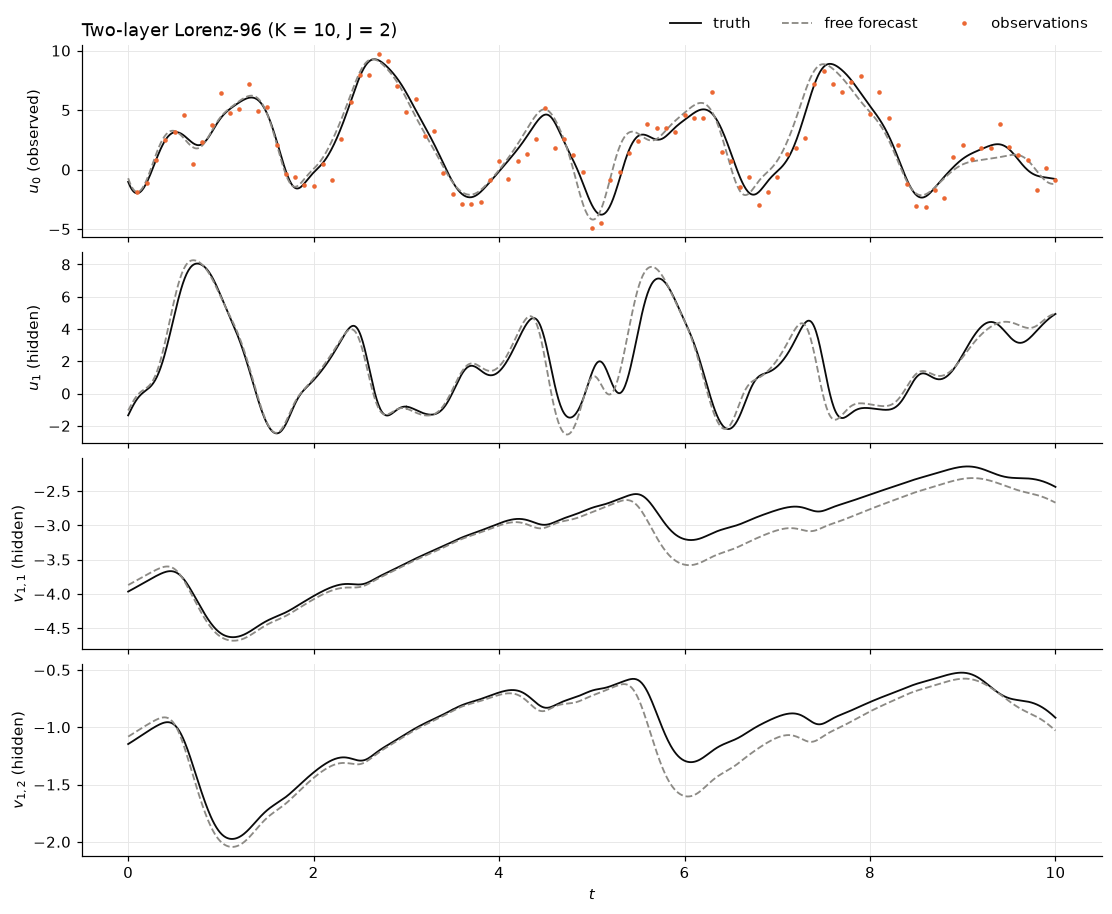

In [6]:
def plot_twin(name, rows):
    mdl, tw = models[name], twins[name]
    t_tr, X_tr = flatten(tw["truth_segments"], hw8.DT_OBS)
    t_fr, X_fr = flatten(tw["free_segments"], hw8.DT_OBS)
    t_obs = hw8.DT_OBS * np.arange(1, hw8.L + 1)
    fig, axes = plt.subplots(len(rows), 1, figsize=(10, 1.9 * len(rows) + 0.6),
                             sharex=True, constrained_layout=True)
    for ax, i in zip(axes, rows):
        ax.plot(t_tr, X_tr[:, i], color=C["truth"], label="truth")
        ax.plot(t_fr, X_fr[:, i], color=C["free"], ls="--", label="free forecast")
        if i in mdl["observed"]:
            j = mdl["observed"].index(i)
            ax.plot(t_obs, tw["Y"][:, j], ".", color=C["obs"], ms=4, label="observations")
            status = "observed"
        else:
            status = "hidden"
        lab = mdl["labels"][i]
        sym = f"$v_{{{lab[1:]}}}$" if lab.startswith("v") else f"$u_{{{lab[1:]}}}$"
        ax.set_ylabel(f"{sym} ({status})")
    axes[0].set_title(mdl["title"], loc="left")
    axes[0].legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=3)
    axes[-1].set_xlabel("$t$")
    return fig

K2 = models["l96_2layer"]["K"]
plot_twin("l96", [0, 1])
plot_twin("l96_2layer", [0, 1, K2 + 2, K2 + 3])   # u0, u1, v1,1, v1,2
plt.show()

## AI use (draft — edit as needed)

Claude (Anthropic) helped write and debug the code for Problem 1: the `hw8.py` module and the code cells in this notebook. The explanation of $D$ is my own.